# Прогноз спроса и выручки для розничной сети

**Задача.** Закупщик заказывает товар по среднему за прошлый месяц. В результате после акций и сезонных пиков на складе копится лишний товар, а в другие недели случается дефицит. Нужен прогноз на 35 дней по каждой паре магазин x SKU, который:

1. точнее текущего способа заказа;
2. даёт три сценария спроса для бюджета закупки;
3. переводится в деньги: сколько запаса и излишков держит сеть при одной и той же политике заказа.

Данные синтетические, структура повторяет выгрузку продаж из 1С (см. `src/generate_data.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import generate_data
from src.config import FIGURES, HORIZON, LEAD_DAYS, REVIEW_DAYS, SALES_FILE, SERVICE_Z
from src.features import demand_segments, load_sales
from src.run_pipeline import FORECASTS_FILE, build_reports, load_backtest, main as run_pipeline

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)

if not SALES_FILE.exists():
    generate_data.main()
df = load_sales()
print(f"{len(df):,} строк, {df['store_id'].nunique()} магазинов, {df['sku_id'].nunique()} SKU, "
      f"период {df['date'].min().date()} : {df['date'].max().date()}")
df.head()

291,840 строк, 8 магазинов, 40 SKU, период 2024-01-01 : 2026-06-30


,date,store_id,sku_id,category,qty,price,regular_price,promo_flag,stock_end,cost_ratio,cost_price,series_id
0,2024-01-01,M1,SKU1000,Напитки,1,290,290,0,6,0.737,213.730,M1_SKU1000
1,2024-01-02,M1,SKU1000,Напитки,2,290,290,0,4,0.737,213.730,M1_SKU1000
2,2024-01-03,M1,SKU1000,Напитки,2,290,290,0,2,0.737,213.730,M1_SKU1000
3,2024-01-04,M1,SKU1000,Напитки,0,290,290,0,19,0.737,213.730,M1_SKU1000
4,2024-01-05,M1,SKU1000,Напитки,0,290,290,0,19,0.737,213.730,M1_SKU1000


## 1. Данные

Дневные продажи в штуках, фактическая и регулярная цена, флаг акции и остаток на конец дня.

In [2]:
summary = pd.Series({
    "Доля дней с промо": df["promo_flag"].mean(),
    "Доля дней без продаж": (df["qty"] == 0).mean(),
    "Доля дней с нулевым остатком": (df["stock_end"] == 0).mean(),
})
summary.to_frame("Значение")

,Значение
Доля дней с промо,0.129
Доля дней без продаж,0.148
Доля дней с нулевым остатком,0.032


В дни с нулевым остатком продажи меньше реального спроса (спрос цензурирован). Такие дни исключаются из обучения LightGBM, иначе модель выучит дефицит как «низкий спрос».

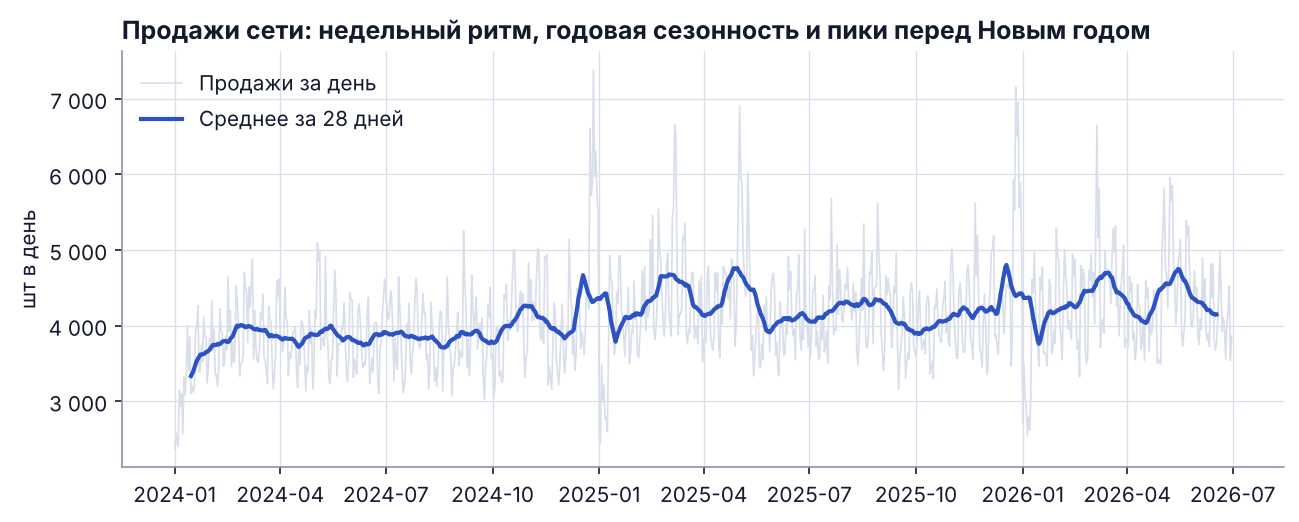

In [3]:
from src import plots
plots.set_style()
plots.plot_sales_overview(df)
display(Image(FIGURES / "01_sales_overview.png"))

### Сегменты спроса

Классификация Syntetos-Boylan по истории до первого окна прогноза: ADI (средний интервал между продажами) и CV² (изменчивость объёма продажи).

In [4]:
from src.evaluate import fold_origins
seg = demand_segments(df, fold_origins()[0])
seg.groupby("segment").agg(рядов=("series_id", "count"), ADI=("adi", "median"), CV2=("cv2", "median"),
                           среднее_шт_в_день=("mean_daily", "median"))

,рядов,ADI,CV2,среднее_шт_в_день
segment,,,,
Комковатый,13,1.406,0.523,1.593
Нерегулярный,97,1.050,0.552,8.221
Прерывистый,74,1.647,0.389,1.093
Стабильный,136,1.029,0.431,11.569


## 2. Модели и бэктест

| Модель | Идея |
|---|---|
| Скользящее среднее 28 дн | Текущая практика: заказ «как в прошлом месяце» |
| Сезонный наивный | Среднее того же дня недели за 4 недели |
| Holt-Winters | Экспоненциальное сглаживание с затухающим трендом и недельной сезонностью, по каждому ряду |
| LightGBM | Глобальная модель по всем рядам: лаги, скользящие средние, календарь, праздники, цена, промо |

Бэктест со скользящим началом: 5 окон по 35 дней в первой половине 2026 года, модель обучается только на данных до начала окна. Все лаги не короче 35 дней, поэтому прогноз на всё окно строится в день его начала без утечки. Окно 0 используется только для калибровки страхового запаса, метрики считаются по окнам 1-4.

Полный пересчёт занимает около 6 минут, поэтому ноутбук берёт сохранённые прогнозы из `reports/`, если они есть.

In [5]:
if not FORECASTS_FILE.exists():
    run_pipeline()
fc, importance = load_backtest()
res = build_reports(df, fc, importance)
res["accuracy"].set_index("Модель")

,"WAPE, день x SKU x магазин","WAPE, неделя x SKU x магазин","WAPE выручки, магазин x неделя",Смещение (bias),"MAE, шт в день"
Модель,,,,,
Скользящее среднее 28 дн,0.527,0.285,0.098,0.004,7.180
Сезонный наивный,0.566,0.285,0.098,0.004,7.722
Holt-Winters,0.529,0.291,0.090,0.004,7.207
LightGBM,0.475,0.202,0.057,-0.022,6.471


**Как читать.** WAPE: сумма абсолютных ошибок, делённая на сумму продаж. На дневном уровне по каждой паре магазин x SKU шум велик для любой модели, поэтому для закупки важнее недельный уровень. Смещение близко к нулю у всех моделей: выигрыш LightGBM в точности распределения спроса по дням и после акций, а не в общем объёме.

In [6]:
res["segments"]

,Скользящее среднее 28 дн,Сезонный наивный,Holt-Winters,LightGBM,Пар ряд x окно
segment,,,,,
Комковатый,0.373,0.373,0.352,0.281,55
Нерегулярный,0.321,0.321,0.342,0.199,390
Прерывистый,0.409,0.409,0.404,0.338,293
Стабильный,0.262,0.262,0.262,0.199,542


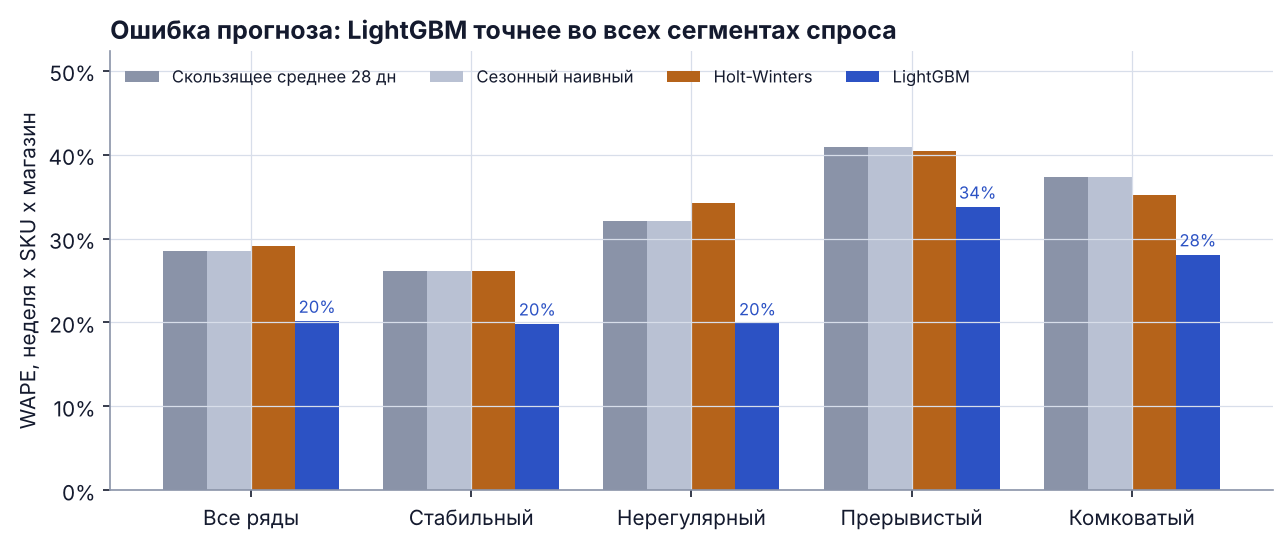

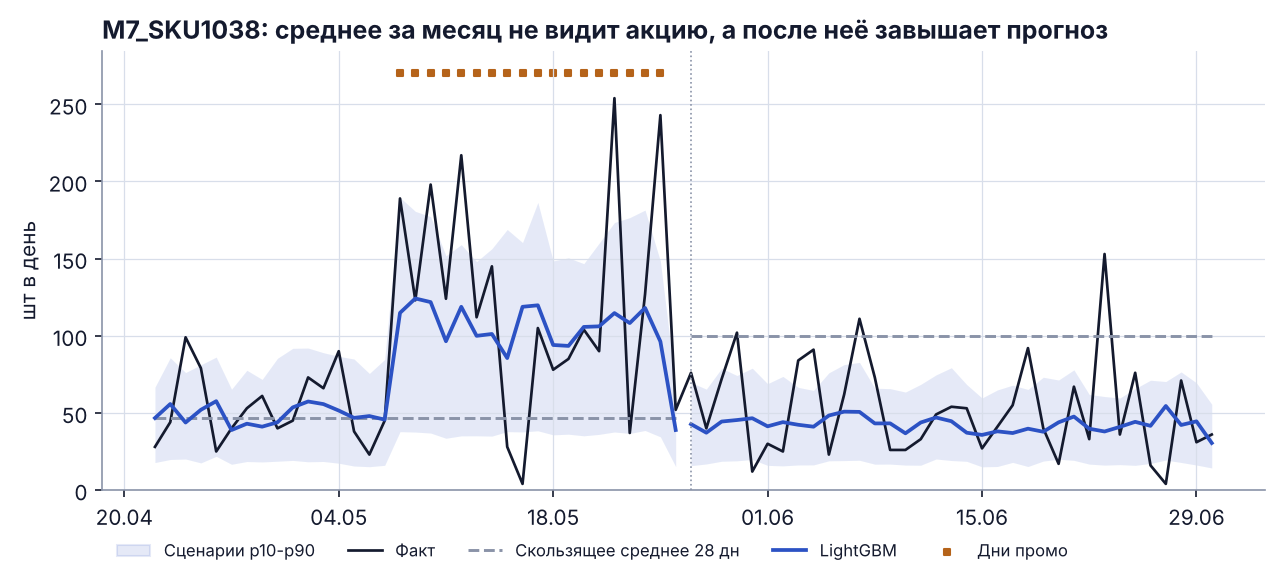

In [7]:
display(Image(FIGURES / "03_wape_by_model.png"))
display(Image(FIGURES / "02_forecast_example.png"))

На примере видно главную проблему ручного заказа: во время акции среднее за месяц занижает спрос, а после акции завышает, потому что в окно попали промо-дни. LightGBM знает о плановой акции и цене, поэтому прогноз возвращается к обычному уровню сразу после её окончания.

## 3. Три сценария спроса

Квантильные модели LightGBM: p10 (пессимистичный), p50 (базовый) и p90 (оптимистичный). Проверка калибровки: при честном коридоре факт должен попадать внутрь p10-p90 примерно в 80% случаев.

In [8]:
pd.Series(res["coverage"]).to_frame("Доля дней")

,Доля дней
Внутри p10-p90,0.753
Ниже p10,0.121
Выше p90,0.126


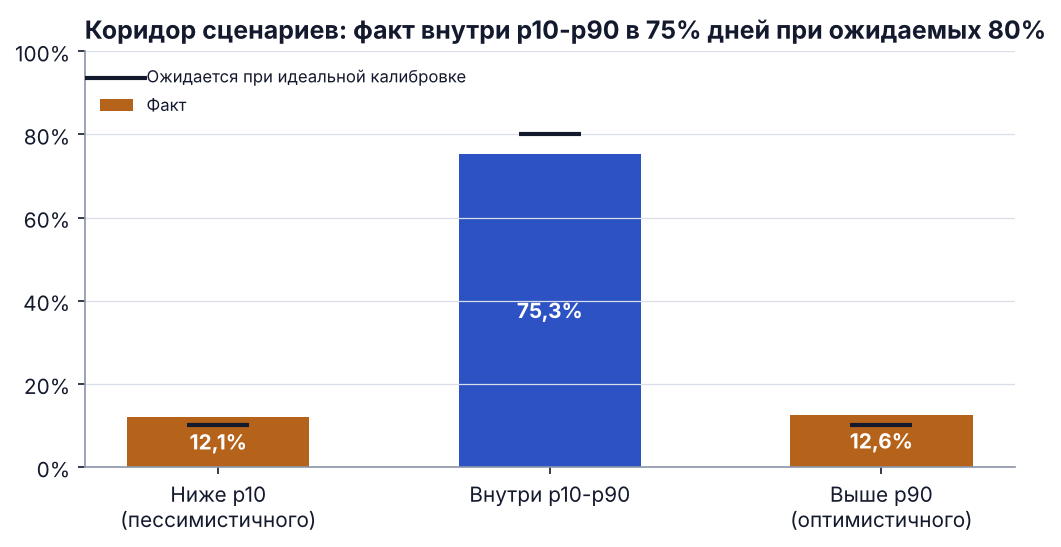

In [9]:
display(Image(FIGURES / "06_scenarios.png"))

## 4. Что точность даёт складу

Одна и та же политика пополнения для всех моделей:

* заказ раз в 7 дней, поставка через 2 дня;
* заказ до уровня: прогноз на 9 дней + страховой запас;
* страховой запас = 1.65 x RMSE модели в предыдущем окне x √9 (целевой сервис около 95%).

Отличается только прогноз. **Излишек** = остаток сверх фактической потребности следующих 9 дней, по себестоимости.

In [10]:
inv = res["inventory"]
inv

,avg_stock_rub,avg_excess_rub,fill_rate,stockout_day_share,lost_sales_rub,turnover_days
Скользящее среднее 28 дн,"3,868,919.130","508,922.865",0.971,0.021,"1,951,610.000",6.808
Сезонный наивный,"3,894,031.608","507,874.633",0.972,0.020,"1,861,570.000",6.819
Holt-Winters,"3,783,025.230","485,416.812",0.969,0.023,"2,185,700.000",6.675
LightGBM,"3,471,514.478","233,990.901",0.991,0.009,"687,810.000",5.971


In [11]:
base, best = inv.iloc[0], inv.loc["LightGBM"]
effect = pd.Series({
    "Излишек, изменение": best["avg_excess_rub"] / base["avg_excess_rub"] - 1,
    "Средний запас, изменение": best["avg_stock_rub"] / base["avg_stock_rub"] - 1,
    "Оборачиваемость, дней было": base["turnover_days"],
    "Оборачиваемость, дней стало": best["turnover_days"],
    "Уровень сервиса было": base["fill_rate"],
    "Уровень сервиса стало": best["fill_rate"],
    "Доля дней дефицита было": base["stockout_day_share"],
    "Доля дней дефицита стало": best["stockout_day_share"],
})
print(f"Сравнение: LightGBM против «{inv.index[0]}»")
effect.to_frame("Значение")

Сравнение: LightGBM против «Скользящее среднее 28 дн»


,Значение
"Излишек, изменение",-0.540
"Средний запас, изменение",-0.103
"Оборачиваемость, дней было",6.808
"Оборачиваемость, дней стало",5.971
Уровень сервиса было,0.971
Уровень сервиса стало,0.991
Доля дней дефицита было,0.021
Доля дней дефицита стало,0.009


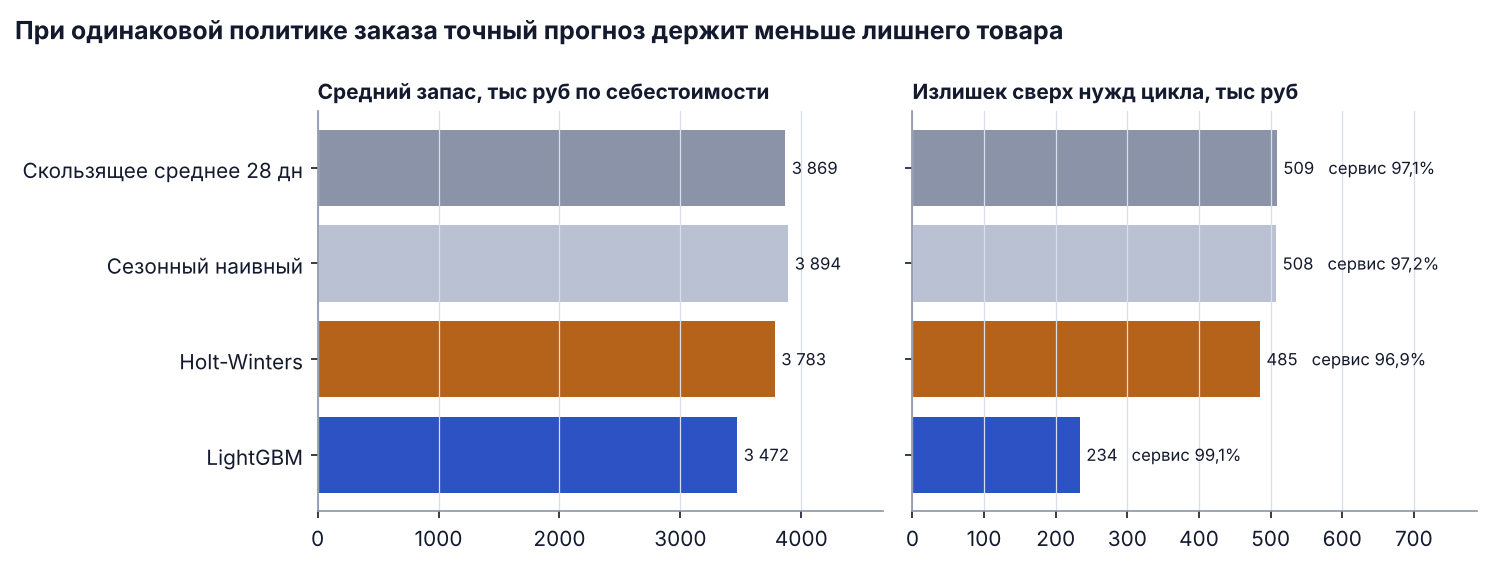

In [12]:
display(Image(FIGURES / "04_inventory_effect.png"))

## 5. Что влияет на прогноз

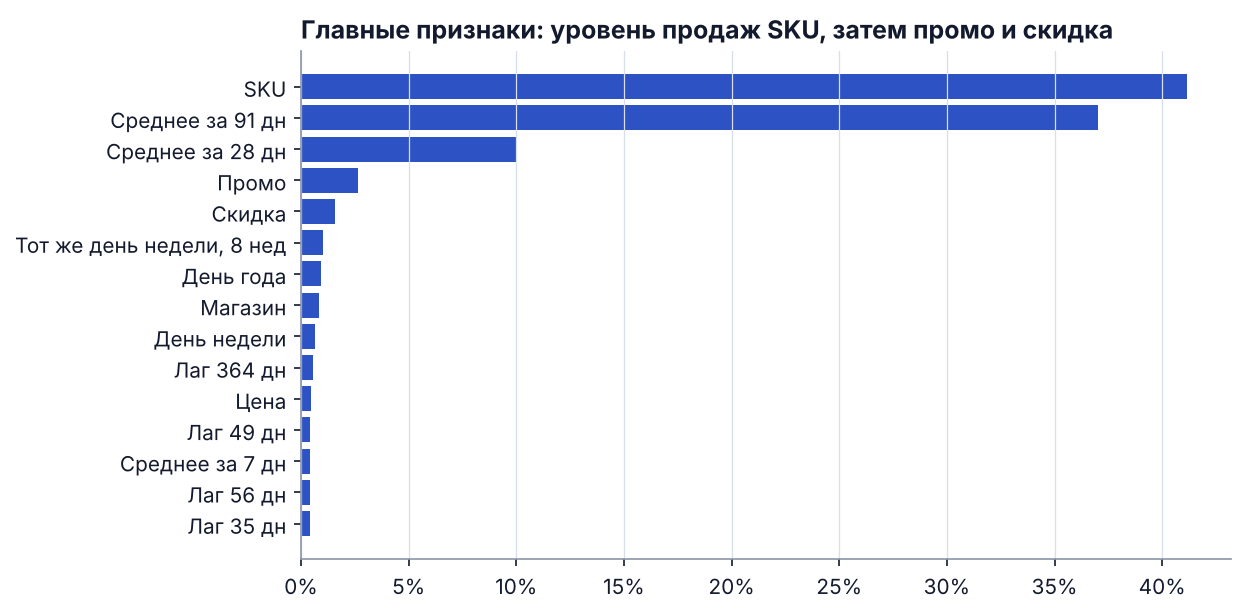

,Доля gain
sku_id,0.411
roll_mean_91,0.370
roll_mean_28,0.100
promo_flag,0.026
discount,0.016
dow_mean_8w,0.010
dayofyear,0.009
store_id,0.008
dow,0.007
lag_364,0.005


In [13]:
display(Image(FIGURES / "05_feature_importance.png"))
importance.head(10).to_frame("Доля gain")

## Выводы

* LightGBM снижает недельную ошибку прогноза по сравнению с заказом по среднему за месяц и выигрывает во всех сегментах спроса, включая прерывистый.
* Главный эффект в деньгах: при той же политике заказа сеть держит заметно меньше излишков и одновременно реже остаётся без товара. Точные значения выведены в таблице выше и в `reports/inventory_effect.csv`.
* Учёт плановых акций убирает типичную ошибку ручного заказа: завышенный заказ сразу после промо.
* Коридор p10-p90 немного уже идеального (факт внутри примерно в 75% дней при ожидаемых 80%), для бюджета закупки его стоит расширить калибровкой на истории.

**Ограничения.** Данные синтетические; спрос в дни дефицита оценивается по продажам, поэтому потерянные продажи занижены одинаково для всех моделей. В реальном внедрении нужно добавить сроки годности, кратность упаковки и минимальную партию поставщика.